# Machine Learning 2026 Spring — HW9 Flow Matching

In this homework, you will train two **flow-based generative models** to transform Gaussian noise into a 2D **Swiss roll** distribution, then use the results to answer the questions on NTU COOL.

You will compare:

1. [**Flow Matching**](https://openreview.net/pdf?id=PqvMRDCJT9t): learns an instantaneous velocity field and usually needs multiple inference steps.
2. [**MeanFlow**](https://openreview.net/pdf?id=uWj4s7rMnR): learns an average velocity and can often generate samples with very few inference steps.

We use **Histogram JS** to measure sample quality, and the final section also compares different Euler step counts and an RK4 solver to show the trade-off between solver cost and sample quality. Please do not change the evaluation settings.

Please make a copy of this notebook before running or editing the code. If you have any technical questions or need clarification, please contact the TA team at ntu-ml-2026-spring-ta@googlegroups.com.

---

## Activate GPU

To enable GPU in Colab:

1. Click **Runtime**.
2. Click **Change runtime type**.
3. Select **T4 GPU** or another GPU.
4. Click **Save**.

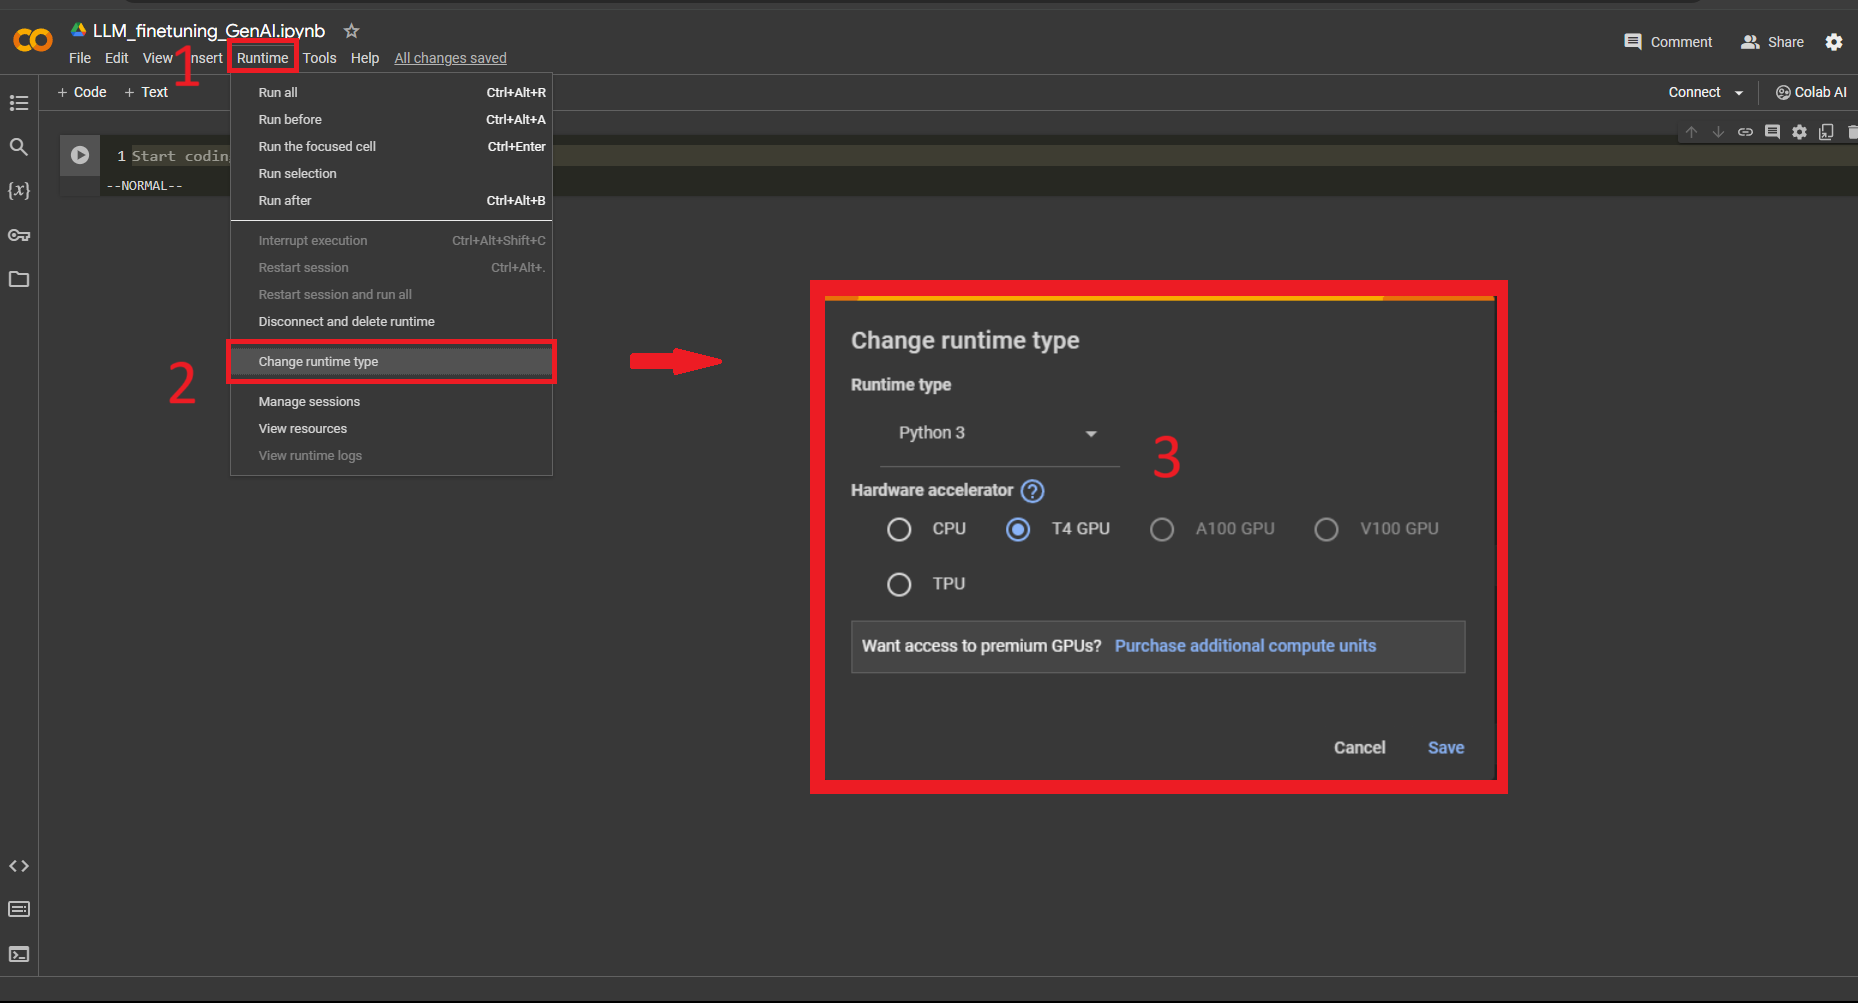

The code can also run on CPU because this is only a small 2D toy example.

## 1. Utilities

We first import packages and define helper functions.

### 1.1 Import packages

In [ ]:
import math
import random
from typing import List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.func import jvp, functional_call
from tqdm.auto import trange


### 1.2 Check device

In [ ]:
!nvidia-smi

Fri May 22 06:10:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 2. Prepare the toy dataset

We use one 2D target distribution: **Swiss roll**.

Each point is a 2D vector `(x, y)`. During training, each model learns to transform Gaussian noise into this target distribution.

### 2.1 Generate Swiss roll data

In [ ]:
def make_swiss_roll(n: int = 20000, noise: float = 0.15, scale: float = 0.45) -> np.ndarray:
    """Create a 2D Swiss roll / spiral dataset without using sklearn.

    Args:
        n: Number of 2D points.
        noise: Standard deviation of Gaussian noise added to the spiral.
        scale: Final scale factor that keeps the samples in a stable visible range.

    Returns:
        A NumPy array with shape (n, 2).
    """
    # t controls the spiral angle and radius.
    t = np.random.uniform(1.5 * np.pi, 4.5 * np.pi, size=n)

    x = t * np.cos(t)
    y = t * np.sin(t)
    samples = np.stack([x, y], axis=1)

    # Add noise so the spiral is not just a thin curve.
    samples += noise * np.random.randn(n, 2)

    # Center and scale the points so most samples fit inside the plot range [-4, 4].
    samples = samples - samples.mean(axis=0, keepdims=True)
    samples = samples / samples.std(axis=0, keepdims=True)
    samples = samples * scale * 3.0

    return samples.astype(np.float32)

target_data = make_swiss_roll(n=20000)
print("Swiss roll dataset shape:", target_data.shape)

Swiss roll dataset shape: (20000, 2)


### 2.2 Visualize the training target first

Before training any model, we should understand the learning goal.

The model starts from a Gaussian noise distribution and should learn to generate samples that look like the Swiss roll target distribution.

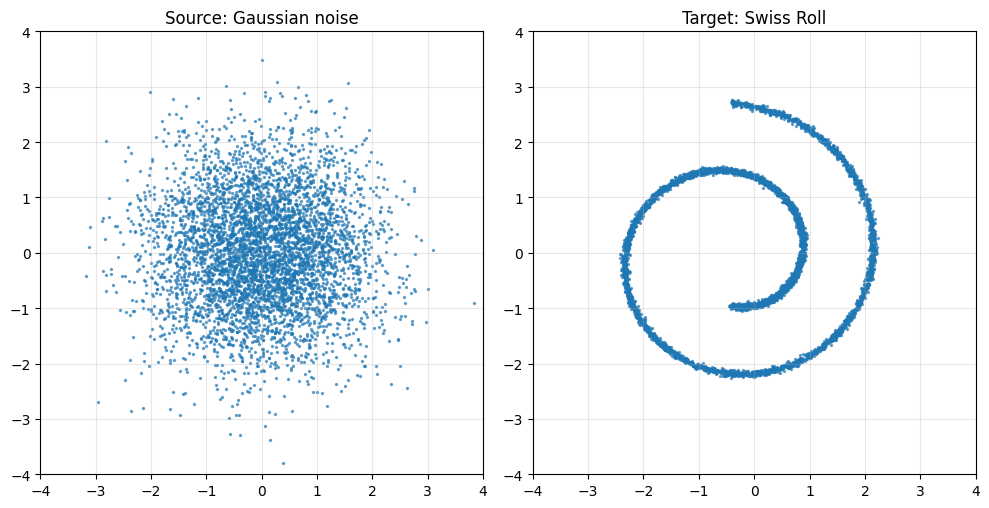

In [ ]:
def plot_samples(samples, title="Samples", ax=None, lim=4.0, s=2, alpha=0.6):
    """Draw 2D samples as a scatter plot."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))

    if isinstance(samples, torch.Tensor):
        samples = samples.detach().cpu().numpy()

    ax.scatter(samples[:, 0], samples[:, 1], s=s, alpha=alpha)
    ax.set_title(title)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    return ax

# Compare the source distribution and the target distribution.
noise = np.random.randn(5000, 2).astype(np.float32)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_samples(noise, "Source: Gaussian noise", axes[0])
plot_samples(target_data[:5000], "Target: Swiss Roll", axes[1])
plt.tight_layout()
plt.show()

### 2.3 What does training try to learn?

For Flow Matching, we create a simple path between a data point $x_0$ and a noise point $x_1$:

$$
x_t = (1 - t)x_0 + tx_1
$$

When $t = 0$, the point is data. When $t = 1$, the point is noise.

The model learns the velocity needed to move along this path:

$$
v = x_1 - x_0
$$

During inference, we start from noise at $t = 1$ and integrate backward to $t = 0$.

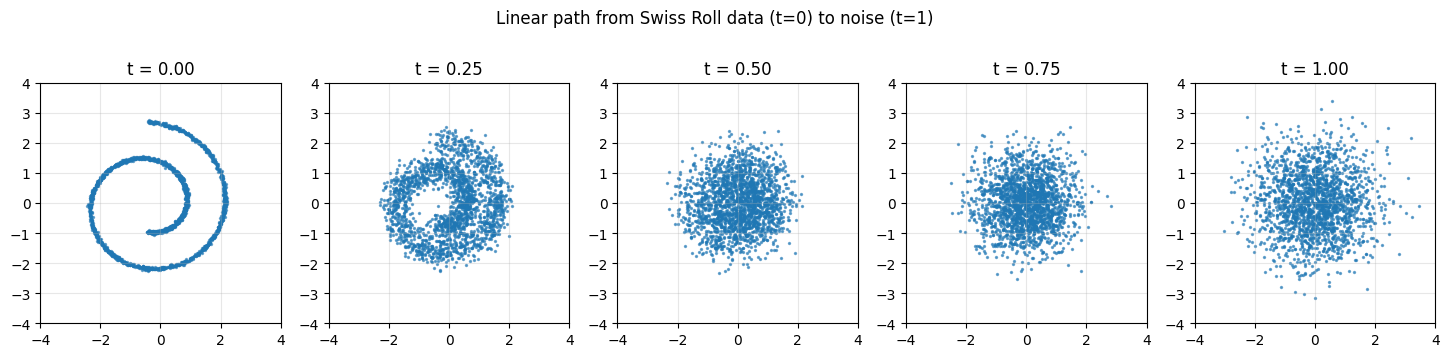

In [ ]:
def show_interpolation_path(data: np.ndarray, num_points: int = 2000):
    """Visualize intermediate points between data and Gaussian noise.

    This cell shows the training target concept:
    data point x0  --->  noise point x1

    During training, the model observes x_t and t, then predicts the velocity from data to noise.
    During sampling, we use the velocity in the reverse direction to move noise back to data.
    """
    num_points = min(num_points, len(data))
    x0 = data[:num_points]
    x1 = np.random.randn(num_points, 2).astype(np.float32)

    t_values = [0.0, 0.25, 0.50, 0.75, 1.0]
    fig, axes = plt.subplots(1, len(t_values), figsize=(18, 4))

    for ax, t in zip(axes, t_values):
        xt = (1 - t) * x0 + t * x1
        plot_samples(xt, f"t = {t:.2f}", ax=ax, lim=4.0, s=2, alpha=0.6)

    plt.suptitle("Linear path from Swiss Roll data (t=0) to noise (t=1)")
    plt.show()

show_interpolation_path(target_data)

### 2.4 Build a PyTorch DataLoader

In [ ]:
# A larger batch size makes training more stable, but also uses more memory.
BATCH_SIZE = 512

def make_dataloader(data: np.ndarray, batch_size: int = BATCH_SIZE) -> DataLoader:
    """Build a DataLoader from a NumPy array of 2D points."""
    # TensorDataset wraps the array so PyTorch can return mini-batches.
    dataset = TensorDataset(torch.from_numpy(data))
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

dataloader = make_dataloader(target_data)
print(f"{len(dataloader)} batches per epoch")

39 batches per epoch


## 3. Prepare Neural Network Models

This section defines the **neural networks** used by Flow Matching and MeanFlow.

Both models are small MLPs. An MLP is a standard feed-forward neural network made of linear layers and nonlinear activation functions.

The job of these networks is not to output a class label. Instead, they output a **2D vector** that tells us how to move a point.

For a point `(x, y)`, the model predicts something like:

```python
[move_in_x_direction, move_in_y_direction]
```

This predicted vector is called a **velocity**. During sampling, we repeatedly use this velocity to move random noise toward the Swiss roll distribution.

There are three parts in this section:

1. `SinusoidalTimeEmbedding`: turns a scalar time value into richer features.
2. `FlowNet`: predicts the instantaneous velocity used by Flow Matching.
3. `MeanFlowNet`: predicts an average velocity over a time interval used by MeanFlow.

---

### 3.1 Time Embedding

The variable `t` tells the model where a point is along the path from data to noise.

- `t = 0` means the point is close to real data.
- `t = 1` means the point is close to Gaussian noise.
- values between 0 and 1 represent intermediate states.

A raw number like `0.37` is often too simple for an MLP to use well. A **time embedding** turns that one number into many features using sine and cosine functions.

The idea is similar to positional embeddings in Transformers: instead of giving the model only the raw position/time, we give it a richer representation of that position/time.

Input and output of this block:

- input: a tensor of time values with shape `(batch,)`
- output: a tensor of time features with shape `(batch, hidden_dim)`

The model will later concatenate these time features with the 2D point coordinates.

In [ ]:
class SinusoidalTimeEmbedding(nn.Module):
    """Convert a scalar time value into a higher-dimensional vector.

    Why do we need this?
    A neural network may have difficulty using a raw scalar t directly.
    A sinusoidal embedding gives the model richer time features.
    """

    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        # Make sure t has shape (batch,).
        t = t.float().view(-1)
        device = t.device

        half_dim = self.dim // 2

        # Frequencies are spread from low to high.
        # This is similar to positional embeddings used in Transformers.
        freq_scale = math.log(10000.0) / max(half_dim - 1, 1)
        freqs = torch.exp(torch.arange(half_dim, device=device) * -freq_scale)

        # Shape: (batch, half_dim)
        args = t[:, None] * freqs[None, :]

        # Concatenate sine and cosine features.
        emb = torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

        # If dim is odd, pad one zero feature.
        if self.dim % 2 == 1:
            emb = torch.cat([emb, torch.zeros(t.shape[0], 1, device=device)], dim=-1)

        return emb

### 3.2 Flow Matching Network

`FlowNet` is the neural network used by Flow Matching.

At training time, Flow Matching creates an intermediate point `x_t` between data and noise. The network receives:

- `x_t`: the current 2D point, shape `(batch, 2)`
- `t`: the current time, shape `(batch,)`

The network outputs:

- a 2D velocity vector, shape `(batch, 2)`

Conceptually, `FlowNet` answers this question:

> At this point and this time, which direction should the point move?

Inside the network:

1. `t` is converted into a time embedding.
2. The 2D point and the time embedding are concatenated.
3. The MLP predicts a 2D velocity.

During sampling, we start from Gaussian noise and repeatedly apply this velocity field with Euler steps to move toward the Swiss roll.

In [ ]:
class FlowNet(nn.Module):
    """MLP for Flow Matching.

    Input:
        x_t: current 2D point at time t
        t: time value in [0, 1]

    Output:
        predicted velocity with shape (batch, 2)
    """

    def __init__(self, hidden_dim: int = 128):
        super().__init__()
        self.time_embed = SinusoidalTimeEmbedding(hidden_dim)

        # The input is 2D point + time embedding.
        self.net = nn.Sequential(
            nn.Linear(2 + hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        t_emb = self.time_embed(t)
        inp = torch.cat([x, t_emb], dim=1)
        return self.net(inp)

### 3.3 MeanFlow Network

`MeanFlowNet` is the neural network used by MeanFlow.

MeanFlow is different from regular Flow Matching because it tries to learn an **average velocity over a time interval** instead of only an instantaneous velocity at one time.

The network receives:

- `z`: the current 2D point, shape `(batch, 2)`
- `r`: the earlier time of the interval, shape `(batch,)`
- `t`: the later time of the interval, shape `(batch,)`

The network outputs:

- an average 2D velocity vector, shape `(batch, 2)`

Conceptually, `MeanFlowNet` answers this question:

> From time `t` to time `r`, what average direction should the point move?

This is why MeanFlow can be evaluated as a one-step generator in this homework. If the model learns a good average velocity from `t = 1` to `r = 0`, it can move from noise to data in one large step.

Inside the network:

1. `r` and `t` are each converted into time embeddings.
2. The 2D point, the `r` embedding, and the `t` embedding are concatenated.
3. The MLP predicts a 2D average velocity.

In [ ]:
class MeanFlowNet(nn.Module):
    """MLP for MeanFlow.

    MeanFlow predicts an average velocity between two times r and t.

    Input:
        z: current 2D point
        r: start time of the interval
        t: end time of the interval

    Output:
        average velocity with shape (batch, 2)
    """

    def __init__(self, hidden_dim: int = 128):
        super().__init__()
        self.time_embed = SinusoidalTimeEmbedding(hidden_dim)

        # The input is 2D point + r embedding + t embedding.
        self.net = nn.Sequential(
            nn.Linear(2 + hidden_dim * 2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, z: torch.Tensor, r: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        r_emb = self.time_embed(r)
        t_emb = self.time_embed(t)
        inp = torch.cat([z, r_emb, t_emb], dim=1)
        return self.net(inp)

## 4. Training-Time Inference Visualization Helper

During training, the notebook periodically samples from the current model and plots **target data** versus **current generated samples**.

The tqdm progress bar also shows:

- current epoch progress,
- current training loss,
- the latest Histogram JS checkpoint,
- the Histogram JS convergence goal.

This makes it easier to notice whether the generated samples are getting closer to the Swiss roll before training finishes.

The scatter plot can use fewer points for readability. The progress-bar Histogram JS uses 5000 samples, so it is comparable to the formal evaluation result.

In [ ]:
def plot_training_inference_snapshot(
    generated_samples: np.ndarray,
    target_samples: np.ndarray,
    method_name: str,
    epoch: int,
    loss_value: float,
    sample_size: int = 2000,
):
    """Plot target samples and current generated samples side by side during training."""
    target_subset = target_samples[:sample_size]
    generated_subset = generated_samples[:sample_size]

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    plot_samples(target_subset, "Target: Swiss Roll", ax=axes[0], s=3, alpha=0.5)
    plot_samples(
        generated_subset,
        f"{method_name}: epoch {epoch}\nloss = {loss_value:.4f}",
        ax=axes[1],
        s=3,
        alpha=0.5,
    )
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def sample_flow_matching_for_monitoring(model: nn.Module, sample_size: int, steps: int) -> np.ndarray:
    """Generate Flow Matching samples during training for visualization."""
    was_training = model.training
    model.eval()

    x = torch.randn(sample_size, 2, device=device)
    dt = 1.0 / steps

    for i in range(steps):
        t_value = 1.0 - i * dt
        t = torch.full((sample_size,), t_value, device=device)
        velocity = model(x, t)
        x = x - dt * velocity

    if was_training:
        model.train()

    return x.cpu().numpy()


@torch.no_grad()
def sample_meanflow_for_monitoring(model: nn.Module, sample_size: int, steps: int) -> np.ndarray:
    """Generate MeanFlow samples during training for visualization."""
    was_training = model.training
    model.eval()

    x = torch.randn(sample_size, 2, device=device)

    for i in range(steps):
        t_value = 1.0 - i / steps
        r_value = 1.0 - (i + 1) / steps

        t = torch.full((sample_size,), t_value, device=device)
        r = torch.full((sample_size,), r_value, device=device)
        avg_velocity = model(x, r, t)
        dt = t_value - r_value
        x = x - dt * avg_velocity

    if was_training:
        model.train()

    return x.cpu().numpy()

## 5. Sampling Functions

These functions are used immediately after each training block for evaluation. The same functions are also reused later for inference-step comparisons.

In [ ]:
@torch.no_grad()
def sample_flow_matching(model: nn.Module, sample_size: int, steps: int) -> np.ndarray:
    """Generate samples with Euler integration.

    This is the default sampler used throughout training and immediate evaluation.
    Alternative solvers are introduced only later, in the final inference-comparison section.

    We start from Gaussian noise at t = 1.
    Then we move backward to t = 0.
    """
    model.eval()

    # Start from Gaussian noise.
    x = torch.randn(sample_size, 2, device=device)

    # Step size for Euler integration.
    dt = 1.0 / steps

    # Move from t=1 to t=0.
    for i in range(steps):
        t_value = 1.0 - i * dt
        t = torch.full((sample_size,), t_value, device=device)

        # The model predicts the velocity from data to noise.
        velocity = model(x, t)

        # Since we sample backward, we subtract the velocity.
        x = x - dt * velocity

    return x.cpu().numpy()


@torch.no_grad()
def sample_meanflow(model: nn.Module, sample_size: int, steps: int) -> np.ndarray:
    """Generate samples with MeanFlow.

    If steps = 1:
        Use one large interval from t=1 to r=0.

    If steps > 1:
        Split [0, 1] into several intervals and apply MeanFlow repeatedly.
    """
    model.eval()

    # Start from Gaussian noise at t=1.
    x = torch.randn(sample_size, 2, device=device)

    # Move backward from t=1 to t=0.
    for i in range(steps):
        t_value = 1.0 - i / steps
        r_value = 1.0 - (i + 1) / steps

        t = torch.full((sample_size,), t_value, device=device)
        r = torch.full((sample_size,), r_value, device=device)

        # Predict average velocity over interval [r, t].
        avg_velocity = model(x, r, t)

        # The interval length is t-r = 1/steps.
        dt = t_value - r_value

        # Move backward by the predicted average velocity.
        x = x - dt * avg_velocity

    return x.cpu().numpy()

## 6. Evaluation Metric Before Training

Before training any model, we first define how we will evaluate sample quality.

In this notebook, we use one distribution-level metric:

**Histogram JS**: lower is better. A value near `0` means the generated samples put probability mass in almost the same places as the target samples.

### 6.1 Intuition

A scatter plot can be hard to compare using one number. Histogram JS turns each scatter plot into a simple density map first:

1. Draw the same square grid over the target plot and the generated plot.
2. Count how many points fall into each grid cell.
3. Divide by the total number of points, so each grid becomes a probability distribution.
4. Compare the two probability distributions using Jensen-Shannon divergence.

For the Swiss roll dataset, this penalizes a spiral that becomes too blurry, too thick, or missing arms.

### 6.2 What Jensen-Shannon Compares

Suppose `p` is the target histogram and `q` is the generated histogram. We first make their average:

$$
m = \frac{1}{2}(p + q)
$$

Then Histogram JS measures how far `p` and `q` are from this average distribution:

$$
JS(p, q) = \frac{1}{2}KL(p || m) + \frac{1}{2}KL(q || m)
$$

You do not need to memorize the formula. The important idea is:

- If the target and generated samples fall into similar grid cells, Histogram JS is small.
- If generated samples put many points in the wrong places, Histogram JS becomes larger.

### 6.3 Convergence Standards

These values are the convergence standards for this homework. They depend on the model size, sample size, and the 64 x 64 histogram grid used in this notebook.

| Method | Convergence standard |
|---:|---:|
| Flow Matching | `Histogram JS <= 0.10` |
| MeanFlow, 1 step | `Histogram JS <= 0.40` |

A model should meet its Histogram JS standard before you continue to the next part. Also inspect the plot, because the plot can catch obvious visual failures that one number may miss.

In [ ]:
def _to_numpy_samples(samples) -> np.ndarray:
    """Convert samples to a NumPy array with shape (number_of_points, 2)."""
    if isinstance(samples, torch.Tensor):
        samples = samples.detach().cpu().numpy()
    return np.asarray(samples, dtype=np.float32)


def histogram_js_distance_2d(
    real_samples: np.ndarray,
    generated_samples: np.ndarray,
    bins: int = 64,
    lim: float = 4.0,
) -> float:
    """Compute Histogram JS between two 2D point clouds.

    Beginner-friendly explanation:
    - `real_samples` is the target point cloud.
    - `generated_samples` is the model output point cloud.
    - We split the visible square [-lim, lim] x [-lim, lim] into bins x bins cells.
    - We count how many points fall into each cell.
    - We normalize the counts so they sum to 1.
    - Finally, we compute Jensen-Shannon divergence between the two histograms.
    """
    real_samples = _to_numpy_samples(real_samples)
    generated_samples = _to_numpy_samples(generated_samples)

    # Step 1: Count points in the same 2D grid for both distributions.
    hist_range = [[-lim, lim], [-lim, lim]]
    real_counts, _, _ = np.histogram2d(
        real_samples[:, 0],
        real_samples[:, 1],
        bins=bins,
        range=hist_range,
    )
    generated_counts, _, _ = np.histogram2d(
        generated_samples[:, 0],
        generated_samples[:, 1],
        bins=bins,
        range=hist_range,
    )

    # Step 2: Flatten each 2D grid into a 1D list of cell probabilities.
    real_prob = real_counts.astype(np.float64).reshape(-1)
    generated_prob = generated_counts.astype(np.float64).reshape(-1)

    # Step 3: Convert counts into probabilities. The sum becomes 1.
    real_prob = real_prob / max(real_prob.sum(), 1.0)
    generated_prob = generated_prob / max(generated_prob.sum(), 1.0)

    # Step 4: Jensen-Shannon uses the average distribution as a reference.
    mixed_prob = 0.5 * (real_prob + generated_prob)

    # Step 5: Compute KL(p || m), but skip cells where p is zero.
    # Zero-probability cells contribute nothing to KL divergence.
    eps = 1e-12

    def kl_divergence(p, q):
        nonzero = p > 0
        return np.sum(p[nonzero] * np.log((p[nonzero] + eps) / (q[nonzero] + eps)))

    js = 0.5 * kl_divergence(real_prob, mixed_prob)
    js += 0.5 * kl_divergence(generated_prob, mixed_prob)

    return float(js)


def compute_distribution_metric(real_samples: np.ndarray, generated_samples: np.ndarray) -> dict:
    """Return the distribution-matching metric used in this notebook."""
    return {
        "Hist_JS": histogram_js_distance_2d(real_samples, generated_samples),
    }


def metric_values_to_columns(values: dict) -> dict:
    """Format metric values as table columns."""
    return {
        "Histogram JS ↓": values["Hist_JS"],
    }


# Convergence standards for this homework.
# These are practical guides for the default model size, sample size, and 64 x 64 histogram grid.
HISTOGRAM_JS_TARGETS = {
    "Flow Matching": 0.10,
    "MeanFlow": 0.40,
}


def get_histogram_js_standard(method_name: str) -> float | None:
    """Return the Histogram JS convergence standard for one method."""
    return HISTOGRAM_JS_TARGETS.get(method_name)


def evaluate_trained_model(
    model: nn.Module,
    method_name: str,
    sample_fn,
    inference_steps: int,
    sample_size: int = 5000,
):
    """Sample from one trained model, plot the result, and display Histogram JS.

    Generate samples, plot them against the target data, and report Histogram JS.
    """
    # Use the same number of real and generated samples for a fair comparison.
    real_eval = target_data[:sample_size]

    # Run inference from Gaussian noise to generated data.
    generated = sample_fn(model, sample_size, inference_steps)

    # Compare real and generated distributions numerically.
    values = compute_distribution_metric(real_eval, generated)

    # Plot target and generated samples side by side.
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    plot_samples(real_eval, "Target: Swiss Roll", ax=axes[0], s=3, alpha=0.5)
    plot_samples(generated, f"{method_name}\n{inference_steps} step(s)", ax=axes[1], s=3, alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Show a compact metric table.
    metric_df = pd.DataFrame([{
        "Dataset": "Swiss Roll",
        "Method": method_name,
        "Inference steps": inference_steps,
        **metric_values_to_columns(values),
    }])
    display(metric_df)

    if method_name == "Flow Matching":
        print("Flow Matching convergence is judged with Euler, 50 inference steps.")
        print("Do not change the Flow Matching inference-step setting to pass this immediate check.")

    standard = get_histogram_js_standard(method_name)
    hist_js = values["Hist_JS"]
    if standard is not None:
        print(f"Convergence standard: Histogram JS <= {standard:.2f}")
        if hist_js <= standard:
            print("Converged by the Histogram JS standard. If the plot also looks reasonable, continue.")
        else:
            print("Not converged yet by the Histogram JS standard.")
            print("Do not continue yet. Increase the epoch setting, train again, and evaluate again.")
    else:
        print("No Histogram JS convergence standard is defined for this setting; judge using the plot and score together.")

    return generated, values

## 7. Training Functions

This section defines the two training procedures used later:

- `train_flow_matching(...)`
- `train_meanflow(...)`

You do not need to edit these functions. For convergence, tune the epoch values in the training blocks.

In [ ]:
def _set_training_progress_postfix(progress, loss_value: float, latest_hist_js=None, target=None):
    """Update the tqdm progress bar with compact training information."""
    postfix = {"loss": f"{loss_value:.4f}"}
    if latest_hist_js is not None:
        postfix["hist_js"] = f"{latest_hist_js:.3f}"
    if target is not None:
        postfix["goal"] = f"<={target:.2f}"
    progress.set_postfix(postfix)


def train_flow_matching(
    model: nn.Module,
    dataloader: DataLoader,
    epochs: int,
    lr: float,
    target_samples: np.ndarray | None = None,
    plot_every: int | None = 50,
    vis_sample_size: int = 5000,
    inference_steps: int = 50,
) -> List[float]:
    """Train a Flow Matching model.

    The model learns v_theta(x_t, t), the velocity at time t.
    In this toy example, the target velocity is simply x1 - x0.

    During training, the tqdm progress bar shows loss and the latest
    formal-size Histogram JS checkpoint. Histogram JS is updated whenever
    the notebook draws a training-time sample plot.
    """
    model.train()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    losses = []
    latest_hist_js = None
    hist_js_target = get_histogram_js_standard("Flow Matching")

    progress = trange(
        epochs,
        desc="Training Flow Matching (Swiss Roll)",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in progress:
        epoch_loss = 0.0

        for (x0,) in dataloader:
            # x0 is real data from the target distribution.
            x0 = x0.to(device)
            batch_size = x0.shape[0]

            # x1 is Gaussian noise.
            x1 = torch.randn_like(x0)

            # Sample random time t in [0, 1].
            t = torch.rand(batch_size, device=device)
            t_view = t.view(-1, 1)

            # Create an intermediate point between data and noise.
            xt = (1.0 - t_view) * x0 + t_view * x1

            # The true velocity along this linear path.
            target_velocity = x1 - x0

            # Predict velocity from the current point and time.
            pred_velocity = model(xt, t)

            # Train with mean squared error.
            loss = loss_fn(pred_velocity, target_velocity)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / len(dataloader)
        losses.append(avg_loss)
        current_epoch = epoch + 1

        should_plot = (
            target_samples is not None
            and plot_every is not None
            and plot_every > 0
            and (current_epoch == 1 or current_epoch % plot_every == 0 or current_epoch == epochs)
        )
        if should_plot:
            generated = sample_flow_matching_for_monitoring(
                model,
                sample_size=vis_sample_size,
                steps=inference_steps,
            )
            # Use the same sample size as the formal evaluation metric, so the
            # progress-bar Histogram JS is comparable to the formal evaluation result.
            metric_sample_size = min(5000, len(target_samples))
            metric_generated = sample_flow_matching_for_monitoring(
                model,
                sample_size=metric_sample_size,
                steps=inference_steps,
            )
            latest_hist_js = histogram_js_distance_2d(
                target_samples[:metric_sample_size],
                metric_generated,
            )
            _set_training_progress_postfix(progress, avg_loss, latest_hist_js, hist_js_target)
            plot_training_inference_snapshot(
                generated_samples=generated,
                target_samples=target_samples,
                method_name="Flow Matching",
                epoch=current_epoch,
                loss_value=avg_loss,
                sample_size=vis_sample_size,
            )
            model.train()
        else:
            _set_training_progress_postfix(progress, avg_loss, latest_hist_js, hist_js_target)

    return losses


def train_meanflow(
    model: nn.Module,
    dataloader: DataLoader,
    epochs: int,
    lr: float,
    target_samples: np.ndarray | None = None,
    plot_every: int | None = 50,
    vis_sample_size: int = 5000,
    inference_steps: int = 1,
) -> List[float]:
    """Train a MeanFlow model.

    This implementation follows the simplified MeanFlow training idea.

    Important variables:
        x0: real data
        x1: Gaussian noise
        t: later time
        r: earlier time
        z: point at time t
        v: basic path velocity from data to noise
        u: model prediction
        dudt: derivative of model prediction with respect to time direction
        target_u: corrected average velocity target

    During training, the tqdm progress bar shows loss and the latest
    formal-size Histogram JS checkpoint. Histogram JS is updated whenever
    the notebook draws a training-time sample plot.
    """
    model.train()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()
    losses = []
    latest_hist_js = None
    hist_js_target = get_histogram_js_standard("MeanFlow")

    # This helper lets jvp evaluate the model functionally.
    # It is useful when computing derivatives through the model output.
    def functional_model(params, buffers, z, r, t):
        return functional_call(model, (params, buffers), (z, r, t))

    progress = trange(
        epochs,
        desc="Training MeanFlow (Swiss Roll)",
        unit="epoch",
        dynamic_ncols=True,
        leave=True,
    )
    for epoch in progress:
        epoch_loss = 0.0

        for (x0,) in dataloader:
            x0 = x0.to(device)
            batch_size = x0.shape[0]

            # Sample Gaussian noise.
            x1 = torch.randn_like(x0)

            # Sample two times r and t.
            # We sort them so r <= t.
            times = torch.rand(batch_size, 2, device=device)
            r = torch.min(times[:, 0], times[:, 1])
            t = torch.max(times[:, 0], times[:, 1])

            r_view = r.view(-1, 1)
            t_view = t.view(-1, 1)

            # z is the point at time t on the linear path.
            z = (1.0 - t_view) * x0 + t_view * x1

            # v is the basic velocity from data to noise.
            v = x1 - x0

            # Compute u and its directional derivative using JVP.
            # Tangent direction:
            #   z changes in direction v
            #   r does not change
            #   t changes with speed 1
            params = dict(model.named_parameters())
            buffers = dict(model.named_buffers())

            u, dudt = jvp(
                lambda z_, r_, t_: functional_model(params, buffers, z_, r_, t_),
                (z, r, t),
                (v, torch.zeros_like(r), torch.ones_like(t)),
            )

            # MeanFlow target.
            # detach() means the target is treated as a fixed label.
            target_u = v - (t_view - r_view) * dudt
            loss = loss_fn(u, target_u.detach())

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / len(dataloader)
        losses.append(avg_loss)
        current_epoch = epoch + 1

        should_plot = (
            target_samples is not None
            and plot_every is not None
            and plot_every > 0
            and (current_epoch == 1 or current_epoch % plot_every == 0 or current_epoch == epochs)
        )
        if should_plot:
            generated = sample_meanflow_for_monitoring(
                model,
                sample_size=vis_sample_size,
                steps=inference_steps,
            )
            # Use the same sample size as the formal evaluation metric, so the
            # progress-bar Histogram JS is comparable to the formal evaluation result.
            metric_sample_size = min(5000, len(target_samples))
            metric_generated = sample_meanflow_for_monitoring(
                model,
                sample_size=metric_sample_size,
                steps=inference_steps,
            )
            latest_hist_js = histogram_js_distance_2d(
                target_samples[:metric_sample_size],
                metric_generated,
            )
            _set_training_progress_postfix(progress, avg_loss, latest_hist_js, hist_js_target)
            plot_training_inference_snapshot(
                generated_samples=generated,
                target_samples=target_samples,
                method_name="MeanFlow",
                epoch=current_epoch,
                loss_value=avg_loss,
                sample_size=vis_sample_size,
            )
            model.train()
        else:
            _set_training_progress_postfix(progress, avg_loss, latest_hist_js, hist_js_target)

    return losses

In [ ]:
# Containers for trained models, losses, samples, and metrics.
# They start empty and are filled by the training and evaluation cells.
flow_model = None
flow_losses = []
flow_samples = None
flow_metrics = None

meanflow_model = None
meanflow_losses = []
meanflow_samples = None
meanflow_metrics = None

## 8. Flow Matching Training Block

In this section, we train **Flow Matching** on Swiss roll.

Flow Matching is evaluated with **Euler sampling and exactly 50 inference steps**. Treat this as the fixed evaluation setting.

Do **not** change the Flow Matching inference-step value just to make the immediate Histogram JS score look better. If the 50-step result does not meet the convergence standard, increase `FLOW_EPOCHS`, train again, and evaluate again.

### 8.1 Train Flow Matching on Swiss Roll

The main value to tune is `FLOW_EPOCHS`. Use more epochs if Flow Matching has not met the convergence standard yet.

You may also change `FLOW_TRAINING_PLOT_EVERY` if you want training-time plots to appear more or less often.

===== Flow Matching: Swiss Roll =====


Training Flow Matching (Swiss Roll):   0%|          | 0/50 [00:00<?, ?epoch/s]

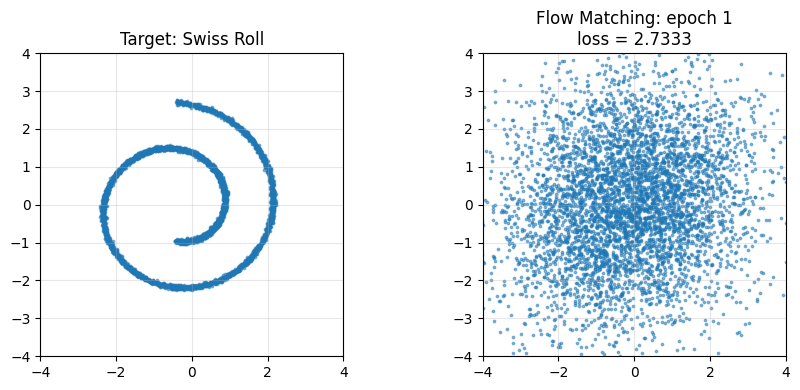

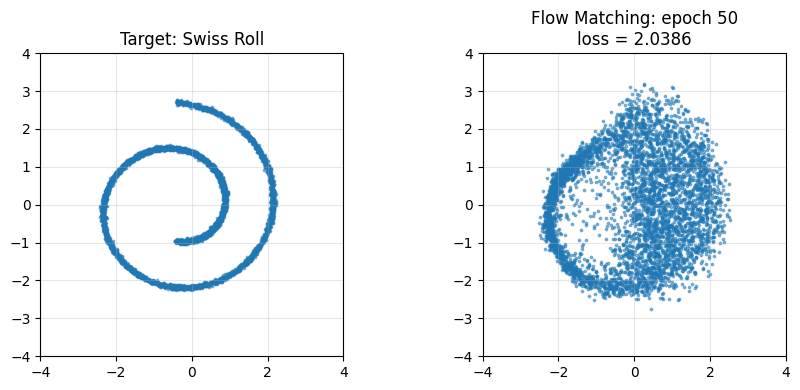

In [ ]:
# ---------------------------
# Parameters: Flow Matching
# ---------------------------
# Increase this if Flow Matching has not met the convergence standard.
FLOW_EPOCHS = 50

# Show training-time sample plots every N epochs.
# Set to None or 0 to turn off intermediate plots.
FLOW_TRAINING_PLOT_EVERY = 50

# Fixed evaluation setting: do not change this to meet the convergence standard.
FLOW_INFERENCE_STEPS = 50

print("===== Flow Matching: Swiss Roll =====")

# Create a fresh Flow Matching model.
flow_model = FlowNet(hidden_dim=128).to(device)

# Train and record the loss curve.
flow_losses = train_flow_matching(
    model=flow_model,
    dataloader=dataloader,
    epochs=FLOW_EPOCHS,
    lr=1e-3,
    target_samples=target_data,
    plot_every=FLOW_TRAINING_PLOT_EVERY,
    vis_sample_size=5000,
    inference_steps=FLOW_INFERENCE_STEPS,
)

### 8.2 Evaluate Swiss Roll Flow Matching Immediately

Use the standard Flow Matching evaluation setting: **Euler, 50 inference steps**.

Do not change `FLOW_INFERENCE_STEPS` to meet the convergence standard. If the result does not meet the convergence standard under 50 steps, increase `FLOW_EPOCHS`, train again, and evaluate again before continuing.

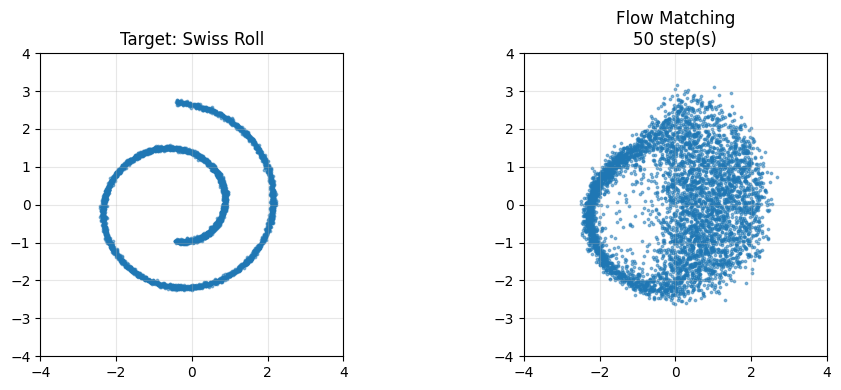

,Dataset,Method,Inference steps,Histogram JS ↓
0,Swiss Roll,Flow Matching,50,0.384376


Flow Matching convergence is judged with Euler, 50 inference steps.
Do not change the Flow Matching inference-step setting to pass this immediate check.
Convergence standard: Histogram JS <= 0.10
Not converged yet by the Histogram JS standard.
Do not continue yet. Increase the epoch setting, train again, and evaluate again.


In [ ]:
# Evaluate immediately after training Flow Matching.
# Standard evaluation setting: Euler sampling with exactly 50 inference steps.
# Do not change FLOW_INFERENCE_STEPS to meet the convergence standard.
# If this plot/metric does not meet the convergence standard, increase FLOW_EPOCHS,
# train again, and evaluate again before continuing.
if flow_model is None:
    print("Train Flow Matching first.")
else:
    flow_samples, flow_metrics = evaluate_trained_model(
        model=flow_model,
        method_name="Flow Matching",
        sample_fn=sample_flow_matching,
        inference_steps=FLOW_INFERENCE_STEPS,
        sample_size=5000,
    )

## 9. MeanFlow Training Block

In this section, we train **MeanFlow** on the same Swiss roll data.

MeanFlow is evaluated as a **one-step generator**. If the one-step samples do not meet the convergence standard, increase `MEANFLOW_EPOCHS`, train again, and evaluate again. Do not increase the number of MeanFlow inference steps.

### 9.1 Train MeanFlow on Swiss Roll

The main value to tune is `MEANFLOW_EPOCHS`. Use more epochs if MeanFlow has not met the convergence standard yet.

You may also change `MEANFLOW_TRAINING_PLOT_EVERY` if you want training-time plots to appear more or less often.

===== MeanFlow: Swiss Roll =====


Training MeanFlow (Swiss Roll):   0%|          | 0/50 [00:00<?, ?epoch/s]

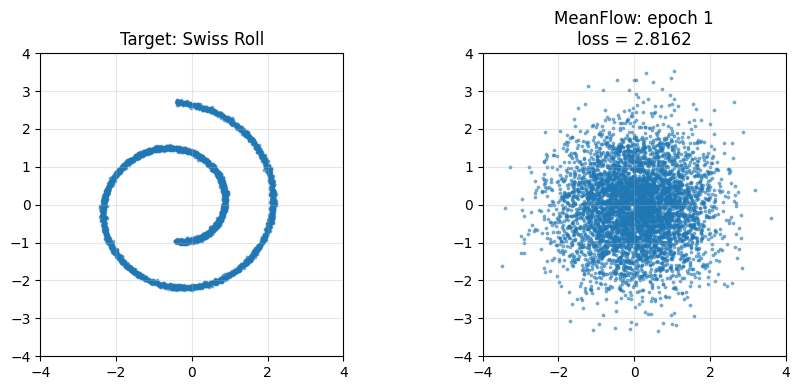

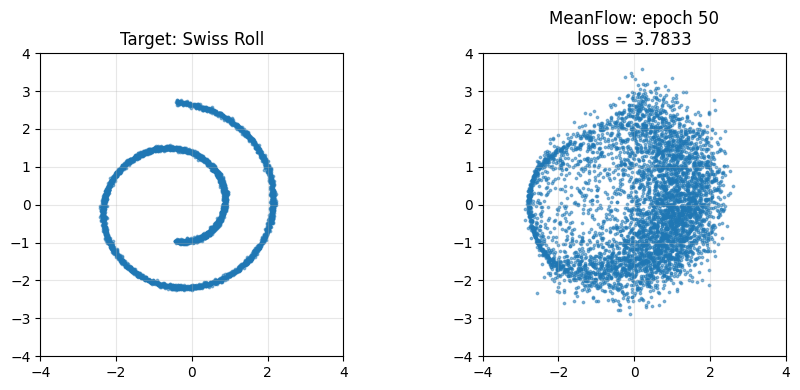

In [ ]:
# ---------------------------
# Parameters: MeanFlow
# ---------------------------
# Increase this if MeanFlow one-step samples have not met the convergence standard.
MEANFLOW_EPOCHS = 50

# Show training-time sample plots every N epochs.
# Set to None or 0 to turn off intermediate plots.
MEANFLOW_TRAINING_PLOT_EVERY = 50

# Fixed evaluation setting: MeanFlow is judged as a one-step generator.
MEANFLOW_INFERENCE_STEPS = 1

print("===== MeanFlow: Swiss Roll =====")

# Create a fresh MeanFlow model.
meanflow_model = MeanFlowNet(hidden_dim=128).to(device)

# Train and record the loss curve.
meanflow_losses = train_meanflow(
    model=meanflow_model,
    dataloader=dataloader,
    epochs=MEANFLOW_EPOCHS,
    lr=1e-3,
    target_samples=target_data,
    plot_every=MEANFLOW_TRAINING_PLOT_EVERY,
    vis_sample_size=5000,
    inference_steps=MEANFLOW_INFERENCE_STEPS,
)

### 9.2 Evaluate Swiss Roll MeanFlow Immediately

Judge convergence using one-step MeanFlow samples. If this result does not meet the convergence standard, increase `MEANFLOW_EPOCHS`, train again, and evaluate again before continuing.

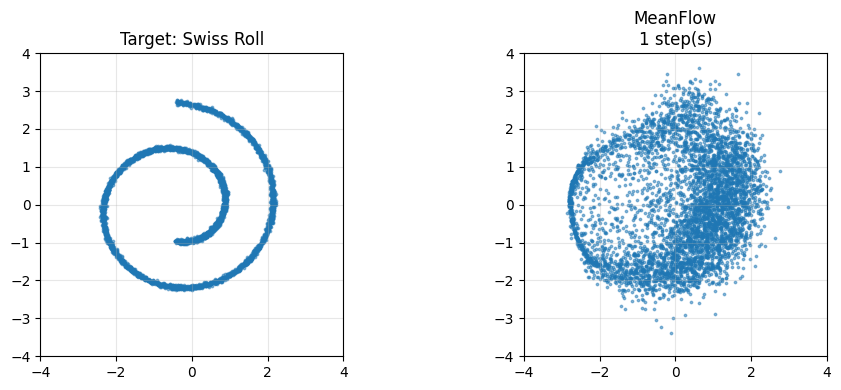

,Dataset,Method,Inference steps,Histogram JS ↓
0,Swiss Roll,MeanFlow,1,0.49398


Convergence standard: Histogram JS <= 0.40
Not converged yet by the Histogram JS standard.
Do not continue yet. Increase the epoch setting, train again, and evaluate again.


In [ ]:
# Evaluate immediately after training MeanFlow.
# Important: MeanFlow convergence is judged by one-step generation.
# If this one-step result does not meet the convergence standard, increase MEANFLOW_EPOCHS,
# train again, and evaluate again before continuing.
# Do not compensate by using more MeanFlow steps.
if meanflow_model is None:
    print("Train MeanFlow first.")
else:
    meanflow_samples, meanflow_metrics = evaluate_trained_model(
        model=meanflow_model,
        method_name="MeanFlow",
        sample_fn=sample_meanflow,
        inference_steps=MEANFLOW_INFERENCE_STEPS,  # fixed to 1 step
        sample_size=5000,
    )

## 10. Training Loss Comparison

Plot the Flow Matching and MeanFlow training losses on the same graph.

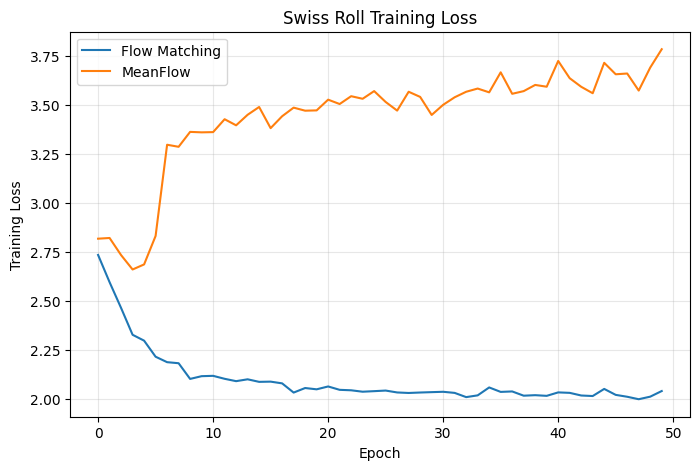

In [ ]:
# Compare training losses only after both methods are trained.
if len(flow_losses) > 0 and len(meanflow_losses) > 0:
    plt.figure(figsize=(8, 5))
    plt.plot(flow_losses, label="Flow Matching")
    plt.plot(meanflow_losses, label="MeanFlow")
    plt.xlabel("Epoch")
    plt.ylabel("Training Loss")
    plt.title("Swiss Roll Training Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("Train both Flow Matching and MeanFlow first.")

## 11. Summary Histogram JS Table

This table collects the immediate evaluation results for Flow Matching and MeanFlow.

In [ ]:
summary_rows = []

if flow_metrics is not None:
    summary_rows.append({
        "Dataset": "Swiss Roll",
        "Method": "Flow Matching",
        "Inference steps": FLOW_INFERENCE_STEPS,
        **metric_values_to_columns(flow_metrics),
    })

if meanflow_metrics is not None:
    summary_rows.append({
        "Dataset": "Swiss Roll",
        "Method": "MeanFlow",
        "Inference steps": MEANFLOW_INFERENCE_STEPS,
        **metric_values_to_columns(meanflow_metrics),
    })

summary_metric_df = pd.DataFrame(summary_rows)
display(summary_metric_df)

,Dataset,Method,Inference steps,Histogram JS ↓
0,Swiss Roll,Flow Matching,50,0.384376
1,Swiss Roll,MeanFlow,1,0.493980


## 12. Final Inference Comparison

Run this section after the immediate Flow Matching and MeanFlow evaluations look reasonable.

The final comparison is split into three ideas:

1. **MeanFlow contribution comparison**: compare **Flow Matching 1-step generation** with **MeanFlow 1-step generation**. This shows why MeanFlow is useful: it is designed to make one-step generation much better than a naive one-step Flow Matching sampler.
2. **Flow Matching Euler step sweep**: compare Flow Matching with different **Euler** inference steps. This shows how ordinary Flow Matching improves when we spend more ODE steps.
3. **Euler vs RK4 comparison with cost**: compare Euler and RK4 in two ways:
   - **Same step count**: Euler 20 steps vs RK4 20 steps.
   - **Similar model-evaluation budget**: Euler 20 steps vs RK4 5 steps, because RK4 uses about 4 model evaluations per step.

Fairness note for the solver comparison:

- Euler uses **1 model evaluation per step**.
- RK4 uses **4 model evaluations per step**.

Therefore, comparing Euler and RK4 only at the same step count is not fully fair, because RK4 is more expensive. The final table reports both approximate model evaluations and measured sampling time.

### 12.1 Define an RK4 Sampler for the Final Comparison

RK4 is a more accurate ODE solver than Euler, but each RK4 step uses about four model evaluations. This function lets us compare sample quality and compute cost.

In [ ]:
@torch.no_grad()
def flow_velocity_at_time(model: nn.Module, x: torch.Tensor, t_value: float) -> torch.Tensor:
    """Evaluate the Flow Matching velocity field at a scalar time value."""
    t = torch.full((x.shape[0],), float(t_value), device=x.device)
    return model(x, t)


@torch.no_grad()
def sample_flow_matching_with_solver(
    model: nn.Module,
    sample_size: int,
    steps: int,
    solver: str = "euler",
) -> np.ndarray:
    """Generate Flow Matching samples with either Euler or RK4.

    This sampler is only used in the final inference comparison.

    Euler:
        One model evaluation per step. Simple and cheap.

    RK4:
        Four model evaluations per step. Usually more accurate per step,
        but more expensive.
    """
    if solver not in ["euler", "rk4"]:
        raise ValueError("solver must be either 'euler' or 'rk4'")

    was_training = model.training
    model.eval()

    # Start from Gaussian noise at t = 1.
    x = torch.randn(sample_size, 2, device=device)

    # We integrate backward from t = 1 to t = 0.
    dt = 1.0 / steps
    h = -dt

    for i in range(steps):
        t_value = 1.0 - i * dt

        if solver == "euler":
            # Euler method:
            # x(t+h) ≈ x(t) + h * v(x(t), t)
            k1 = flow_velocity_at_time(model, x, t_value)
            x = x + h * k1

        else:
            # Fourth-order Runge-Kutta method:
            # Estimate the velocity at four points inside one interval.
            k1 = flow_velocity_at_time(model, x, t_value)
            k2 = flow_velocity_at_time(model, x + 0.5 * h * k1, t_value + 0.5 * h)
            k3 = flow_velocity_at_time(model, x + 0.5 * h * k2, t_value + 0.5 * h)
            k4 = flow_velocity_at_time(model, x + h * k3, t_value + h)
            x = x + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

    if was_training:
        model.train()

    return x.cpu().numpy()


### 12.2 Main Comparison: Flow Matching 1-Step vs MeanFlow 1-Step

This is the key comparison for MeanFlow.

A regular Flow Matching model usually needs multiple ODE steps during inference. If we force it to use only **one Euler step**, the generated distribution is often poor. MeanFlow is trained so that **one-step generation** can already produce a reasonable distribution.

So this block compares:

- target distribution
- Flow Matching with **Euler, 1 step**
- MeanFlow with **1 step**

If MeanFlow works well, its one-step samples should be much closer to the target than Flow Matching one-step samples.

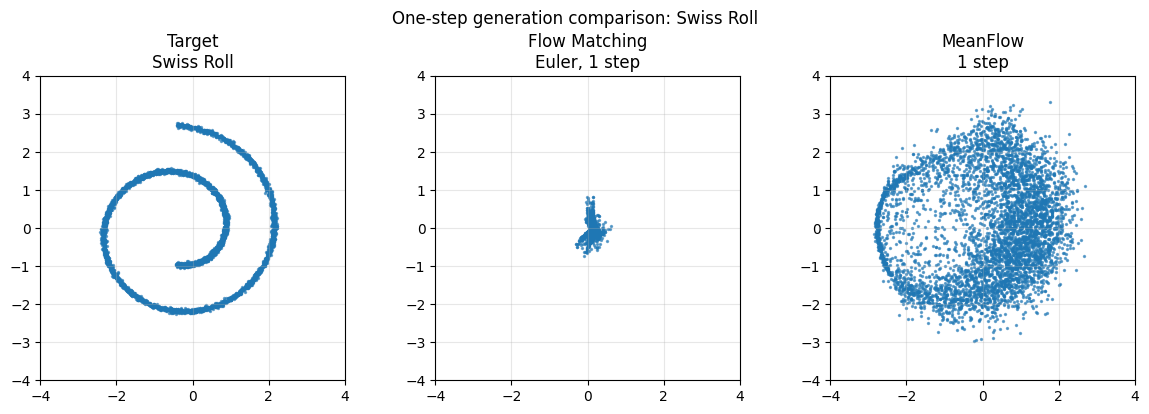

,Dataset,Method,Inference setting,Approx. model evaluations,Histogram JS ↓
0,Swiss Roll,Flow Matching,"Euler, 1 step",1,0.693147
1,Swiss Roll,MeanFlow,1 step,1,0.492581


In [ ]:
# Main MeanFlow contribution comparison.
# We intentionally compare both methods under the same one-step inference budget.
# This makes the contribution of MeanFlow clear: it is designed to improve one-step generation.

one_step_comparison_rows = []
comparison_sample_size = 5000
meanflow_eval_steps = 1
flow_one_step_solver = "euler"
flow_one_step_steps = 1

if flow_model is None or meanflow_model is None:
    print("Train both models first.")
else:
    real_eval = target_data[:comparison_sample_size]

    # Flow Matching with only one Euler step.
    # This is usually too few steps for a standard Flow Matching model,
    # which is exactly why it is a useful baseline against MeanFlow.
    flow_1step_samples = sample_flow_matching_with_solver(
        flow_model,
        comparison_sample_size,
        flow_one_step_steps,
        solver=flow_one_step_solver,
    )

    # MeanFlow is always evaluated as a one-step generator in this homework.
    meanflow_1step_samples = sample_meanflow(
        meanflow_model,
        comparison_sample_size,
        meanflow_eval_steps,
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    plot_samples(real_eval, "Target\nSwiss Roll", ax=axes[0])
    plot_samples(flow_1step_samples, "Flow Matching\nEuler, 1 step", ax=axes[1])
    plot_samples(meanflow_1step_samples, "MeanFlow\n1 step", ax=axes[2])
    plt.suptitle("One-step generation comparison: Swiss Roll")
    plt.tight_layout()
    plt.show()

    flow_values = compute_distribution_metric(real_eval, flow_1step_samples)
    meanflow_values = compute_distribution_metric(real_eval, meanflow_1step_samples)

    one_step_comparison_rows.append({
        "Dataset": "Swiss Roll",
        "Method": "Flow Matching",
        "Inference setting": "Euler, 1 step",
        "Approx. model evaluations": 1,
        **metric_values_to_columns(flow_values),
    })
    one_step_comparison_rows.append({
        "Dataset": "Swiss Roll",
        "Method": "MeanFlow",
        "Inference setting": "1 step",
        "Approx. model evaluations": 1,
        **metric_values_to_columns(meanflow_values),
    })

one_step_comparison_df = pd.DataFrame(one_step_comparison_rows)
display(one_step_comparison_df)

### 12.3 Secondary Comparison: Flow Matching Inference Steps and RK4 Cost Tradeoff

This section asks:

> If we allow Flow Matching to use more inference computation, how much does generation improve?

It uses three stages:

1. **Euler step sweep**: compare Flow Matching with different Euler step counts.
2. **Same-step Euler vs RK4**: compare Euler and RK4 using the same number of ODE steps.
3. **Similar-compute Euler vs RK4**: compare Euler and RK4 using approximately the same number of model evaluations.

The third stage matters because RK4 is not free. RK4 uses four model calls per ODE step, so RK4 with 20 steps costs roughly the same as Euler with 80 steps.

MeanFlow is not included in this solver/step sweep because its role in this homework is one-step generation.

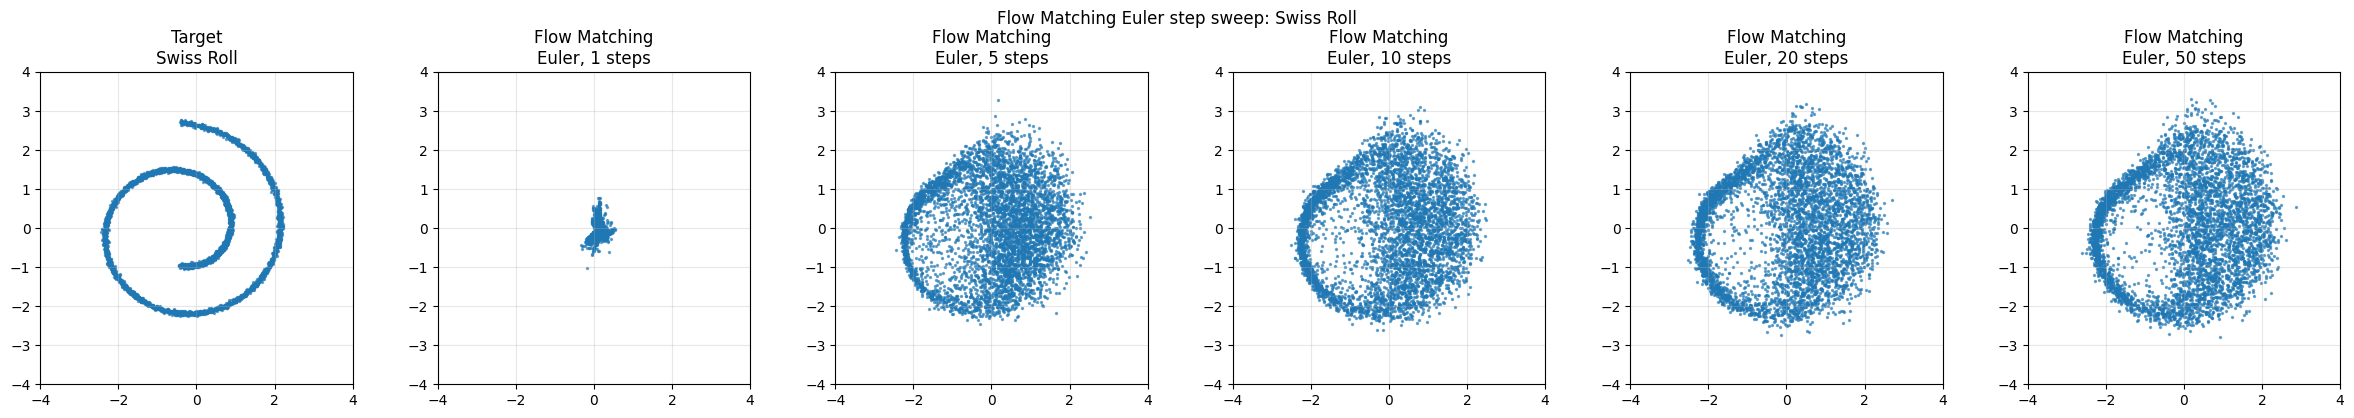

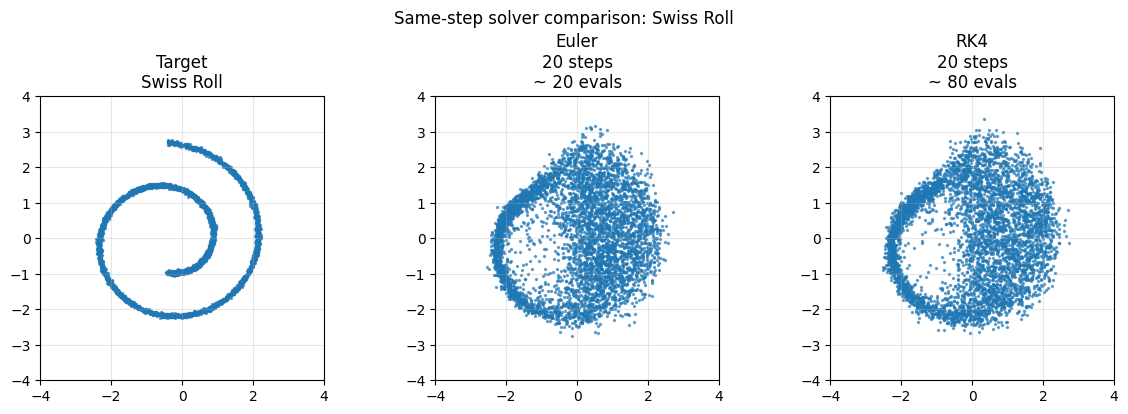

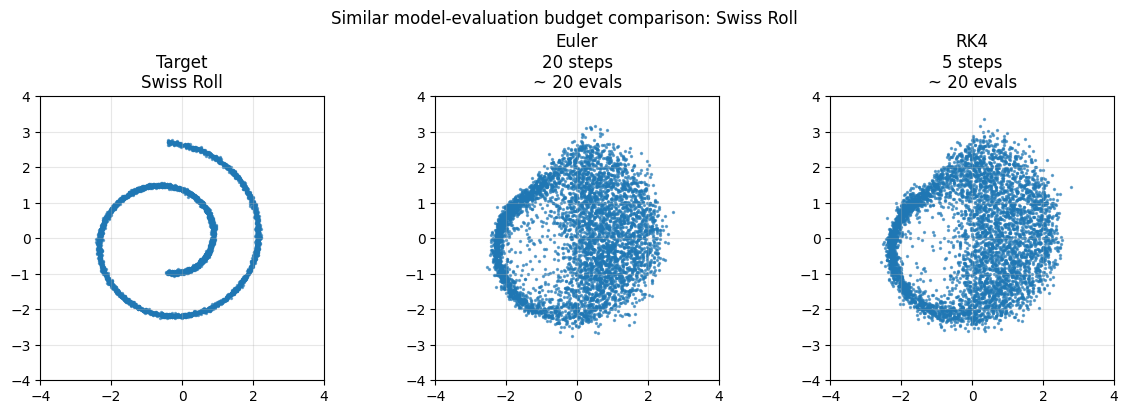

,Dataset,Method,Comparison type,ODE solver,Inference steps,Approx. model evaluations,Sampling time (s),Histogram JS ↓
0,Swiss Roll,Flow Matching,Euler step sweep,euler,1,1,0.0013,0.692612
1,Swiss Roll,Flow Matching,Euler step sweep,euler,5,5,0.0034,0.441772
2,Swiss Roll,Flow Matching,Euler step sweep,euler,10,10,0.0057,0.404403
3,Swiss Roll,Flow Matching,Euler step sweep,euler,20,20,0.0110,0.380183
4,Swiss Roll,Flow Matching,Euler step sweep,euler,50,50,0.0267,0.382966
5,Swiss Roll,Flow Matching,"Euler vs RK4, same step",rk4,20,80,0.0544,0.377844
6,Swiss Roll,Flow Matching,"Euler vs RK4, same step",euler,20,20,0.0110,0.380183
7,Swiss Roll,Flow Matching,"Euler vs RK4, similar model-eval budget",euler,20,20,0.0110,0.380183
8,Swiss Roll,Flow Matching,"Euler vs RK4, similar model-eval budget",rk4,5,20,0.0133,0.382324


In [ ]:
# Secondary Flow Matching-only comparison.
# Teaching goal:
#   1. Use Euler to show how increasing the number of inference steps improves Flow Matching.
#   2. Use RK4 only as a reference solver.
#   3. Compare not only sample quality, but also inference cost.
#
# Why cost matters:
#   - Euler uses about 1 model evaluation per ODE step.
#   - RK4 uses about 4 model evaluations per ODE step.
# Therefore, "Euler 20 steps vs RK4 20 steps" is a same-step comparison,
# but RK4 uses about 4x more model calls. A fairer cost comparison is
# "Euler 20 steps vs RK4 5 steps", because both use about 20 model calls.

import time

EULER_STEP_LIST = [1, 5, 10, 20, 50]

# Same-step comparison: both solvers use this many ODE steps.
RK4_SAME_STEP_COMPARISON_STEPS = 20

# Similar-compute comparison: RK4 uses 4 model evaluations per step,
# so RK4 5 steps has roughly the same model-evaluation budget as Euler 20 steps.
EULER_BUDGET_COMPARISON_STEPS = 20
RK4_BUDGET_COMPARISON_STEPS = max(1, EULER_BUDGET_COMPARISON_STEPS // 4)

flow_solver_metric_rows = []
comparison_sample_size = 5000


def timed_flow_sample(model, sample_size, steps, solver):
    """Sample from a Flow Matching model and measure wall-clock inference time."""
    start_time = time.perf_counter()
    samples = sample_flow_matching_with_solver(
        model,
        sample_size,
        steps,
        solver=solver,
    )
    elapsed_time = time.perf_counter() - start_time
    return samples, elapsed_time


def add_flow_metric_row(comparison_type, solver, steps, samples, elapsed_time, real_eval):
    """Compute Histogram JS and append one row to the comparison table."""
    values = compute_distribution_metric(real_eval, samples)
    model_evals_per_step = 1 if solver == "euler" else 4
    flow_solver_metric_rows.append({
        "Dataset": "Swiss Roll",
        "Method": "Flow Matching",
        "Comparison type": comparison_type,
        "ODE solver": solver,
        "Inference steps": steps,
        "Approx. model evaluations": model_evals_per_step * steps,
        "Sampling time (s)": elapsed_time,
        **metric_values_to_columns(values),
    })


if flow_model is None:
    print("Train the Flow Matching model first.")
else:
    real_eval = target_data[:comparison_sample_size]

    # ------------------------------------------------------------
    # Stage 1: Euler step sweep
    # ------------------------------------------------------------
    # This is the main inference-step comparison for Flow Matching.
    # Observe whether more Euler steps make the generated distribution
    # closer to the target distribution, and how inference time grows.
    euler_results_by_step = {}

    n_cols = 1 + len(EULER_STEP_LIST)
    fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 4))
    plot_samples(real_eval, "Target\nSwiss Roll", ax=axes[0])

    for col, steps in enumerate(EULER_STEP_LIST, start=1):
        samples, elapsed_time = timed_flow_sample(
            flow_model,
            comparison_sample_size,
            steps,
            solver="euler",
        )
        euler_results_by_step[steps] = {
            "samples": samples,
            "elapsed_time": elapsed_time,
        }
        plot_samples(samples, f"Flow Matching\nEuler, {steps} steps", ax=axes[col])

        add_flow_metric_row(
            comparison_type="Euler step sweep",
            solver="euler",
            steps=steps,
            samples=samples,
            elapsed_time=elapsed_time,
            real_eval=real_eval,
        )

    plt.suptitle("Flow Matching Euler step sweep: Swiss Roll")
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # Stage 2: same-step Euler vs RK4
    # ------------------------------------------------------------
    # This answers: if Euler and RK4 use the same number of ODE steps,
    # does RK4 improve sample quality?
    # But remember: RK4 has about 4x model evaluations under the same step count.
    same_step = RK4_SAME_STEP_COMPARISON_STEPS

    if same_step in euler_results_by_step:
        euler_same_step_samples = euler_results_by_step[same_step]["samples"]
        euler_same_step_time = euler_results_by_step[same_step]["elapsed_time"]
    else:
        euler_same_step_samples, euler_same_step_time = timed_flow_sample(
            flow_model,
            comparison_sample_size,
            same_step,
            solver="euler",
        )
        add_flow_metric_row(
            comparison_type="Euler vs RK4, same step",
            solver="euler",
            steps=same_step,
            samples=euler_same_step_samples,
            elapsed_time=euler_same_step_time,
            real_eval=real_eval,
        )

    rk4_same_step_samples, rk4_same_step_time = timed_flow_sample(
        flow_model,
        comparison_sample_size,
        same_step,
        solver="rk4",
    )
    add_flow_metric_row(
        comparison_type="Euler vs RK4, same step",
        solver="rk4",
        steps=same_step,
        samples=rk4_same_step_samples,
        elapsed_time=rk4_same_step_time,
        real_eval=real_eval,
    )

    # Add the Euler row for the same-step table even if it already appeared in the sweep.
    # This duplicate row is intentional because it makes the RK4 comparison table easier to read.
    add_flow_metric_row(
        comparison_type="Euler vs RK4, same step",
        solver="euler",
        steps=same_step,
        samples=euler_same_step_samples,
        elapsed_time=euler_same_step_time,
        real_eval=real_eval,
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    plot_samples(real_eval, "Target\nSwiss Roll", ax=axes[0])
    plot_samples(euler_same_step_samples, f"Euler\n{same_step} steps\n~ {same_step} evals", ax=axes[1])
    plot_samples(rk4_same_step_samples, f"RK4\n{same_step} steps\n~ {4 * same_step} evals", ax=axes[2])
    plt.suptitle("Same-step solver comparison: Swiss Roll")
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # Stage 3: similar model-evaluation budget comparison
    # ------------------------------------------------------------
    # This is often the fairer solver comparison.
    # Euler 20 steps ~ 20 model evaluations.
    # RK4 5 steps ~ 20 model evaluations.
    euler_budget_steps = EULER_BUDGET_COMPARISON_STEPS
    rk4_budget_steps = RK4_BUDGET_COMPARISON_STEPS

    if euler_budget_steps in euler_results_by_step:
        euler_budget_samples = euler_results_by_step[euler_budget_steps]["samples"]
        euler_budget_time = euler_results_by_step[euler_budget_steps]["elapsed_time"]
    else:
        euler_budget_samples, euler_budget_time = timed_flow_sample(
            flow_model,
            comparison_sample_size,
            euler_budget_steps,
            solver="euler",
        )

    rk4_budget_samples, rk4_budget_time = timed_flow_sample(
        flow_model,
        comparison_sample_size,
        rk4_budget_steps,
        solver="rk4",
    )

    add_flow_metric_row(
        comparison_type="Euler vs RK4, similar model-eval budget",
        solver="euler",
        steps=euler_budget_steps,
        samples=euler_budget_samples,
        elapsed_time=euler_budget_time,
        real_eval=real_eval,
    )
    add_flow_metric_row(
        comparison_type="Euler vs RK4, similar model-eval budget",
        solver="rk4",
        steps=rk4_budget_steps,
        samples=rk4_budget_samples,
        elapsed_time=rk4_budget_time,
        real_eval=real_eval,
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    plot_samples(real_eval, "Target\nSwiss Roll", ax=axes[0])
    plot_samples(euler_budget_samples, f"Euler\n{euler_budget_steps} steps\n~ {euler_budget_steps} evals", ax=axes[1])
    plot_samples(rk4_budget_samples, f"RK4\n{rk4_budget_steps} steps\n~ {4 * rk4_budget_steps} evals", ax=axes[2])
    plt.suptitle("Similar model-evaluation budget comparison: Swiss Roll")
    plt.tight_layout()
    plt.show()

flow_solver_metric_df = pd.DataFrame(flow_solver_metric_rows)

# Round the measured time for readability. Exact timing can vary across machines.
if len(flow_solver_metric_df) > 0:
    flow_solver_metric_df["Sampling time (s)"] = flow_solver_metric_df["Sampling time (s)"].round(4)

display(flow_solver_metric_df)